# CDC-CP: predict the crop and the disease apart, then join them into a pair

CDC-CP predicts the **crop** and the **disease** of a leaf with separate models, then scores every crop-disease pair.
This notebook trains every model from scratch (seed 42) and reports three phases. Each phase changes one thing from the one before.

| Phase | Crop models | Disease models | What changes |
|---|---|---|---|
| Baseline 1 | ConvNeXt-Tiny | ConvNeXt-Tiny | team baseline (numbers from the team baseline notebook) |
| **P1** | ConvNeXt-Tiny | ConvNeXt-Tiny | the Baseline 1 design retrained here: stop after 5 epochs with no better dev HM, flip averaging at test; gamma only in the calibrated rows |
| **P2** | ConvNeXt-Tiny | **CLIP ViT-B/16** | CLIP replaces the disease model: text prompts name each disease |
| **P3** | ConvNeXt-Tiny **+ CLIP ViT-B/16** | CLIP ViT-B/16 **+ ConvNeXt-Small** | 2 models per task, averaged |

**How a phase picks the answer**
1. **Crop score:** the log-probability of each crop (P3: the mean of its two crop models).
2. **Disease score:** the same for each disease.
3. **Pair score** = crop score + disease score. The best pair is the answer. This is the **raw** result (no calibration).
4. **Calibration (second result):** take gamma off every pair seen in training, so the unseen pairs can win.
   gamma is chosen on the development split only, for each phase on its own.

Five models are trained in total. The crop ConvNeXt-Tiny is used in all three phases and the disease CLIP in P2 and P3.
Each phase is tested once.

## Model settings

| Setting | ConvNeXt-Tiny (crop, disease) | ConvNeXt-Small (disease) | CLIP ViT-B/16 (crop, disease) |
|---|---|---|---|
| Start weights | ImageNet | ImageNet | OpenAI CLIP |
| Head | dropout (0.3 crop, 0.2 disease) + linear | dropout 0.2 + linear | frozen text prompts (4 per class) + a learned scale |
| Loss | cross-entropy | cross-entropy, label smoothing 0.1 | cross-entropy |
| Augmentation | random crop 224 (area 85-100%), horizontal and vertical flip, rotation ±10°, brightness and contrast ±0.15 | "strong": crop area 30-100%, flips, TrivialAugmentWide, random erasing (p 0.25) | same as ConvNeXt-Tiny, with CLIP's own colour normalisation |
| Weight decay | 0.001 | 0.05 | 0.1 |
| Stochastic depth | 0.1 (torchvision default) | 0.4 | none |

Same for every model:

| Setting | Value |
|---|---|
| Optimiser, batch | AdamW, 16 images |
| Learning rate (backbone / head) | stage 1: 1e-5 / 1e-3; stage 2: 1e-6 / 1e-4 |
| Stage 1 | 6,905 dev-train images; at most 25 epochs, cosine (T_max 30), no warm-up; stop after 5 epochs with no new best dev HM (seen and unseen Top-1 of the model's own task); keep the best epoch |
| Stage 2 | all 8,000 training images; 10 epochs, cosine (T_max 10); keep the epoch with the best training accuracy |
| Evaluation | resize 256, centre crop 224; flip averaging (each image and its mirror) for the dev outputs behind gamma and for the test |
| Mixed precision, seed | on, 42 |

Section 2 prints these settings again, read from the training code.

## Calibration (gamma) in plain words

- The development split hides 10 crop-disease pairs from training (400 images), like the real test hides its 10 unseen pairs.
- Raw scores almost always prefer a pair seen in training. Taking **gamma** off every seen pair lets unseen pairs win.
- **Rule 1 "keep seen" (main calibrated result):** the gamma with the best dev unseen accuracy while dev seen accuracy drops at most 3 points.
- **Rule 2 "best dev HM":** the gamma (and disease weight r, 0.5 to 2) with the best dev HM.
- gamma is saved to Drive **before** the test files are read. The test never changes gamma.
- Calibration needs the list of possible pairs (333 = 323 seen + 10 unseen). The raw 9,625-pair result does not.

## Before you run

1. Google Drive folder `My Drive/DPD-Small/` holds: `DPD_Small_dataset/`, `DPD_Small_train.csv`, `DPD_Small_test_seen.csv`,
   `DPD_Small_test_unseen.csv`, and `cdc-cp_code_final_model.zip`.
2. Runtime > Change runtime type > **A100 GPU** (L4 also works, but slower) > Save. Then Runtime > **Run all**. Allow Drive access.
3. Keep the tab open until the last cell prints "Finished".
4. Results go to `My Drive/DPD-Small/final_model_results/`. A folder from an earlier try is renamed, never deleted.
   Each try keeps its five final models there: leave about 1.5 GB free on Drive.
5. To run again after a change of the code zip: Runtime > **Restart session** first, then Run all.

Time (guesses): about 85-100 minutes on an A100; about 100-130 minutes on an L4.

## 1. Setup

In [1]:
# Settings for this run
import os
from pathlib import Path

STAGE1_EPOCHS, PATIENCE = 25, 5            # stage 1: at most 25 epochs, stop after 5 with no new best dev HM
STAGE2_EPOCHS = 10                         # stage 2: 10 epochs on all 8,000 images
AMP, FLIP, PRETRAINED = True, True, True   # half precision, mirror-image averaging, pretrained weights
MAX_TRAIN_BATCHES = None                   # None = full epochs
DEVICE_NAME = 'cuda'
WORKERS = max(2, min(12, ((os.cpu_count() or 4) - 2) // 2))   # image-loading processes per training job
GPU_JOBS = {(0, 0): ['disease_small_reg', 'crop_b1', 'disease_b1'],  # two lanes share the one GPU;
            (0, 1): ['disease_clip', 'crop_clip']}                   # each lane trains its models one after the other
EXPECT_IMAGES, EXPECT_TEST, TEST_NOT_IN_TRAIN = 11448, (2000, 1448), True

DRIVE_DIR = Path('/content/drive/MyDrive/DPD-Small')
DRIVE_RESULTS = DRIVE_DIR / 'final_model_results'
INPUT, OUT, CODE_DIR = Path('/content/data'), Path('/content/final_model'), Path('/tmp/cdc-cp')
CODE_ZIP = 'cdc-cp_code_final_model.zip'
EXPECTED_CODE_SHA = '0777e2f70c39689ae087dcf501d8aca86cf7d1c87d6ab97483aec6a18787c864'

In [2]:
# Connect Google Drive and unpack the project code
import shutil, sys, time, zipfile
import torch
from google.colab import drive
assert DEVICE_NAME != 'cuda' or torch.cuda.is_available(), 'no GPU: Runtime > Change runtime type > A100 or L4 GPU'
drive.mount('/content/drive')

stamp = time.strftime('%Y%m%d_%H%M%S')
for folder in (DRIVE_RESULTS, OUT):            # an earlier try is kept under a new name
    if folder.exists():
        folder.rename(folder.with_name(f'{folder.name}_earlier_{stamp}'))
unzip_dir = CODE_DIR.parent / 'code_unzip'
for folder in (CODE_DIR, unzip_dir):
    if folder.exists():
        shutil.rmtree(folder)
with zipfile.ZipFile(DRIVE_DIR / CODE_ZIP) as archive:
    archive.extractall(unzip_dir)
shutil.move(str(next(unzip_dir.rglob('final_model.py')).parent.parent), CODE_DIR)
sys.path.insert(0, str(CODE_DIR))

from cdccp import final_model as fm, calibration as cb, ensemble as ens, single_task as st
from cdccp.catalogue import load_catalogue
from cdccp.colab_io import check_images, copy_tree, save_results
from cdccp.gpu_runner import run_on_gpus
assert fm.code_fingerprint(CODE_DIR) == EXPECTED_CODE_SHA, f'{CODE_ZIP} is not the code version this notebook was built for'
print('code version', EXPECTED_CODE_SHA[:12], 'OK')

Mounted at /content/drive
code version 0777e2f70c39 OK


In [3]:
# Copy the images and CSVs to this machine, load the development split
IMAGES = INPUT / 'DPD_Small_dataset'
copy_tree(DRIVE_DIR / 'DPD_Small_dataset', IMAGES)
n_images = check_images(IMAGES)                # opens every image once, so a damaged copy stops the run now
assert n_images >= EXPECT_IMAGES, f'{n_images} images open; expected {EXPECT_IMAGES}'
for name in ('DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv'):
    shutil.copy2(DRIVE_DIR / name, INPUT / name)   # the test CSVs are only read in section 6

TRAIN_CSV, SPLITS = INPUT / 'DPD_Small_train.csv', CODE_DIR / 'data' / 'splits_v2'
fm.check_inputs(TRAIN_CSV, SPLITS)             # the Baseline 1 train CSV and development split
train_fit, val_seen, val_unseen = st.load_dev(SPLITS)
CROP_IDS, DISEASE_IDS = st.class_ids(train_fit, val_seen, val_unseen)
assert CROP_IDS == list(range(55)) and DISEASE_IDS == list(range(175)), 'column j of each head must be class id j'
DEVICE = torch.device(DEVICE_NAME)
print(f'{n_images} images | dev split: train {len(train_fit)}, seen {len(val_seen)}, unseen {len(val_unseen)} '
      f'| {len(CROP_IDS)} crops, {len(DISEASE_IDS)} diseases')
print('GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'none', '| CPUs:', os.cpu_count(), '| workers per job:', WORKERS)

copied 11448 of 11448 files from /content/drive/MyDrive/DPD-Small/DPD_Small_dataset to /content/data/DPD_Small_dataset in 419 s (sizes checked)
11448 images | dev split: train 6905, seen 695, unseen 400 | 55 crops, 175 diseases
GPU: NVIDIA L4 | CPUs: 12 | workers per job: 5


## 2. The five models: settings and quick checks

In [4]:
# Settings read from the code, then one-minute checks (weights, half precision, CLIP zero-shot) before hours of training
TRAINED = fm.check_jobs(GPU_JOBS)
display(fm.member_settings())
for phase, tasks in fm.PHASES.items():
    print(f"{phase}: crop {' + '.join(tasks['crop'])} | disease {' + '.join(tasks['disease'])}")
for aug in ('b1', 'strong'):
    print(f'train transform "{aug}":', st.train_transform(aug))
print('test transform:', st.eval_transform())

DEV_ALL = (train_fit, val_seen, val_unseen)
CLASS_NAMES = {'crop': st.names_in_order('crop', DEV_ALL, CROP_IDS, True),
               'disease': st.names_in_order('disease', DEV_ALL, DISEASE_IDS, True)}
fm.preflight(TRAINED, DEVICE, AMP, PRETRAINED, val_seen, IMAGES, CLASS_NAMES)

,model,task,backbone,augmentation,head,stage 1 lr (backbone / head),stage 2 lr (backbone / head),weight decay,label smoothing,stochastic depth
0,crop_b1,crop,convnext_tiny,b1,dropout 0.3 + linear,1e-05 / 0.001,1e-06 / 0.0001,0.001,0.0,0.1
1,disease_b1,disease,convnext_tiny,b1,dropout 0.2 + linear,1e-05 / 0.001,1e-06 / 0.0001,0.001,0.0,0.1
2,disease_clip,disease,clip_vit_b16,b1,frozen text prompts + learned scale,1e-05 / 0.001,1e-06 / 0.0001,0.100,0.0,0.0
3,crop_clip,crop,clip_vit_b16,b1,frozen text prompts + learned scale,1e-05 / 0.001,1e-06 / 0.0001,0.100,0.0,0.0
4,disease_small_reg,disease,convnext_small,strong,dropout 0.2 + linear,1e-05 / 0.001,1e-06 / 0.0001,0.050,0.1,0.4


P1: crop crop_b1 | disease disease_b1
P2: crop crop_b1 | disease disease_clip
P3: crop crop_b1 + crop_clip | disease disease_clip + disease_small_reg
train transform "b1": Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.85, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
train transform "strong": Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.3, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), st

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (21 outputs left out)

CLIP zero-shot disease on dev seen, before training: 2.73% (chance 0.57%)


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0

CLIP half precision OK for batches (1, 8, 15, 16, 17, 32)


## 3. Stage 1: train on the development split (6,905 images), keep the best dev epoch

In [5]:
# Stage 1: two lanes at the same time, each trains its models in turn
STAGE1, RESULTS = OUT / 'stage1', OUT / 'results'
RESULTS.mkdir(parents=True, exist_ok=True)

def stage1_command(arm):
    return fm.job_command('stage1', arm, splits=SPLITS, images=IMAGES, out=STAGE1, epochs=STAGE1_EPOCHS, patience=PATIENCE,
                          workers=WORKERS, device=DEVICE_NAME, amp=AMP, pretrained=PRETRAINED, max_batches=MAX_TRAIN_BATCHES)

start = time.time()
try:
    run_on_gpus(GPU_JOBS, stage1_command, OUT / 'logs_stage1', CODE_DIR, budget_hours=8, report_seconds=120)
finally:
    save_results(OUT, DRIVE_RESULTS)           # the logs reach Drive even if a job fails
print(f'Stage 1 finished in {(time.time() - start) / 60:.0f} min')

[17:39] disease_small_reg: [disease_small_reg] epoch 1/25 train=0.4957 seen=0.6647 unseen=0.1475 h=0.2414 best_h=0.2414@1 94s eta 37m36s
[17:39] disease_clip: [disease_clip] epoch 1/25 train=0.5573 seen=0.6432 unseen=0.2700 h=0.3803 best_h=0.3803@1 94s eta 37m39s
[17:41] disease_small_reg: [disease_small_reg] epoch 2/25 train=0.7182 seen=0.7050 unseen=0.1650 h=0.2674 best_h=0.2674@2 83s eta 33m54s
[17:41] disease_clip: [disease_clip] epoch 2/25 train=0.7660 seen=0.6460 unseen=0.2775 h=0.3882 best_h=0.3882@2 97s eta 36m43s
[17:43] disease_small_reg: [disease_small_reg] epoch 4/25 train=0.8097 seen=0.7712 unseen=0.1925 h=0.3081 best_h=0.3119@3 82s eta 30m00s
[17:43] disease_clip: [disease_clip] epoch 3/25 train=0.8494 seen=0.7295 unseen=0.2950 h=0.4201 best_h=0.4201@3 97s eta 35m15s
[17:45] disease_small_reg: [disease_small_reg] epoch 5/25 train=0.8293 seen=0.7655 unseen=0.2375 h=0.3625 best_h=0.3625@5 84s eta 28m28s
[17:45] disease_clip: [disease_clip] epoch 4/25 train=0.8953 seen=0.703

,arm,task,aug,backbone,recipe,best_epoch,seen_acc,unseen_acc,individual_h,seen_correct,seen_n,unseen_correct,unseen_n
0,disease_small_reg,disease,strong,convnext_small,reg,21,0.8086,0.2675,0.4020,562,695,107,400
1,crop_b1,crop,b1,convnext_tiny,b1,10,0.9022,0.7275,0.8055,627,695,291,400
2,disease_b1,disease,b1,convnext_tiny,b1,5,0.7511,0.2500,0.3751,522,695,100,400
3,disease_clip,disease,b1,clip_vit_b16,clip,13,0.7741,0.3275,0.4603,538,695,131,400
4,crop_clip,crop,b1,clip_vit_b16,clip,9,0.8993,0.7125,0.7951,625,695,285,400


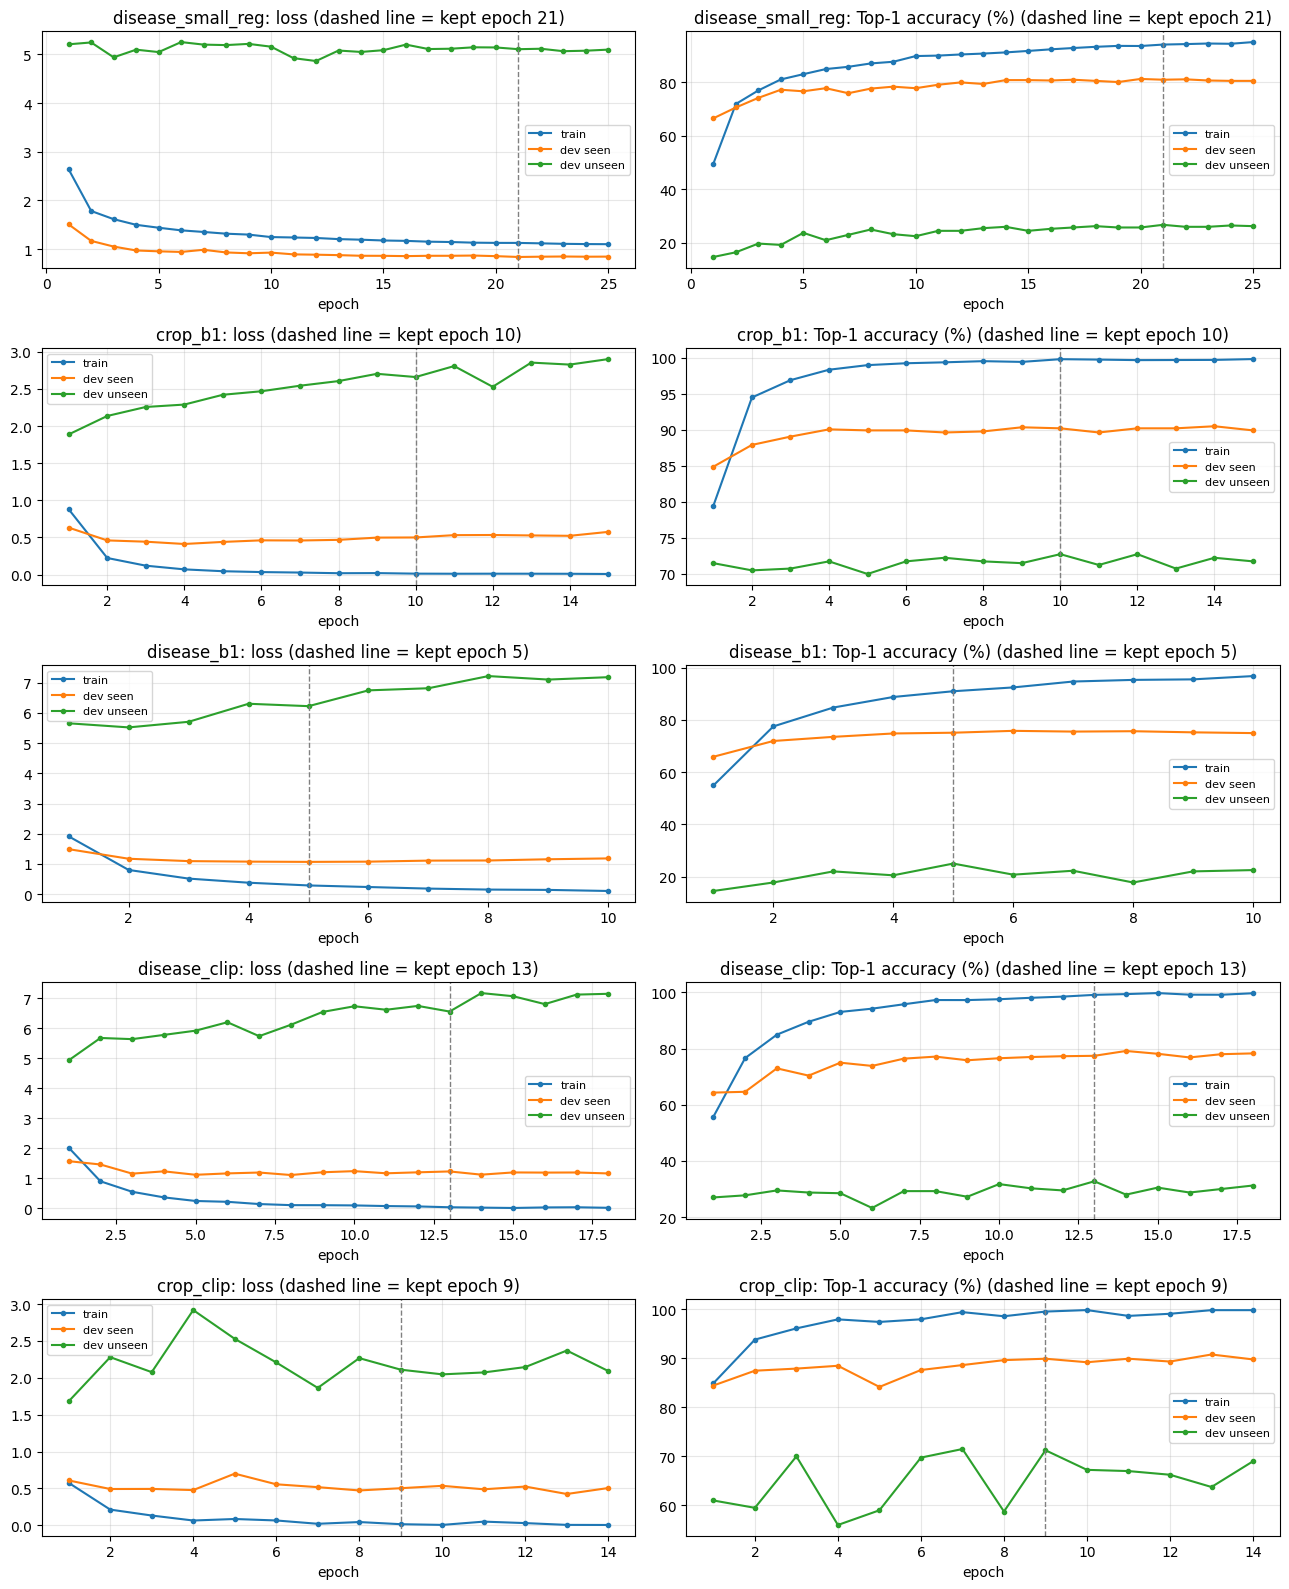

In [6]:
# Stage 1 results: best epoch of each model, and its loss and accuracy curves
import json
import matplotlib.pyplot as plt
import pandas as pd

board = st.stage1_board(STAGE1, TRAINED)
board.to_csv(RESULTS / 'dev_stage1_board.csv', index=False)
display(board.round(4))

fig, axes = plt.subplots(len(TRAINED), 2, figsize=(13, 3.2 * len(TRAINED)), squeeze=False)
for row, arm in zip(axes, TRAINED):
    h = pd.read_csv(STAGE1 / arm / 'history.csv')
    for col, label in (('train_loss', 'train'), ('seen_loss', 'dev seen'), ('unseen_loss', 'dev unseen')):
        row[0].plot(h.epoch, h[col], marker='o', ms=3, label=label)
    for col, label in (('train_acc', 'train'), ('seen_acc', 'dev seen'), ('unseen_acc', 'dev unseen')):
        row[1].plot(h.epoch, 100 * h[col], marker='o', ms=3, label=label)
    best = json.loads((STAGE1 / arm / 'done.json').read_text())['best_epoch']
    for ax, title in zip(row, ('loss', 'Top-1 accuracy (%)')):
        ax.axvline(best, color='grey', ls='--', lw=1)
        ax.set_title(f'{arm}: {title} (dashed line = kept epoch {best})')
        ax.set_xlabel('epoch')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'stage1_curves.png', dpi=150)
plt.show()

In [7]:
# Dev predictions of the five stage-1 best models (with flip averaging), used to choose gamma in section 5
import numpy as np
DEV_LOGP = fm.predict_members({arm: STAGE1 / arm / 'best.pt' for arm in TRAINED}, {'seen': val_seen, 'unseen': val_unseen},
                              IMAGES, CROP_IDS, DISEASE_IDS, DEVICE, AMP, WORKERS, FLIP)
np.savez_compressed(RESULTS / 'dev_flip_logprobs.npz', **{f'{a}_{s}': v for (a, s), v in DEV_LOGP.items()})
save_results(OUT, DRIVE_RESULTS)

saved 110 new or changed files to /content/drive/MyDrive/DPD-Small/final_model_results


110

## 4. Stage 2: 10 more epochs on all 8,000 training images

In [8]:
STAGE2 = OUT / 'stage2'

def stage2_command(arm):
    return fm.job_command('stage2', arm, stage1=STAGE1, train_csv=TRAIN_CSV, images=IMAGES, out=STAGE2, epochs=STAGE2_EPOCHS,
                          workers=WORKERS, device=DEVICE_NAME, amp=AMP, max_batches=MAX_TRAIN_BATCHES)

start = time.time()
try:
    run_on_gpus(GPU_JOBS, stage2_command, OUT / 'logs_stage2', CODE_DIR, report_seconds=120)
finally:
    save_results(OUT, DRIVE_RESULTS, model_folders=('stage2',))   # the five final models reach Drive here
print(f'Stage 2 finished in {(time.time() - start) / 60:.0f} min')
display(fm.stage2_summary(STAGE2, TRAINED).round(2))

[18:39] disease_small_reg: [disease_small_reg] stage2 epoch 1/10 train=0.8918 best=0.8918@1 92s eta 13m45s
[18:39] disease_clip: [disease_clip] stage2 epoch 1/10 train=0.9544 best=0.9544@1 110s eta 16m25s
[18:41] disease_small_reg: [disease_small_reg] stage2 epoch 2/10 train=0.9002 best=0.9002@2 91s eta 12m10s
[18:41] disease_clip: [disease_clip] stage2 epoch 2/10 train=0.9780 best=0.9780@2 109s eta 14m32s
[18:43] disease_small_reg: [disease_small_reg] stage2 epoch 3/10 train=0.9034 best=0.9034@3 91s eta 10m39s
[18:43] disease_clip: [disease_clip] stage2 epoch 3/10 train=0.9865 best=0.9865@3 108s eta 12m40s
[18:45] disease_small_reg: [disease_small_reg] stage2 epoch 5/10 train=0.9109 best=0.9109@5 91s eta 7m36s
[18:45] disease_clip: [disease_clip] stage2 epoch 4/10 train=0.9930 best=0.9930@4 108s eta 10m51s
[18:47] disease_small_reg: [disease_small_reg] stage2 epoch 6/10 train=0.9124 best=0.9124@6 92s eta 6m05s
[18:47] disease_clip: [disease_clip] stage2 epoch 5/10 train=0.9971 best=0.

,model,started from stage-1 epoch,kept stage-2 epoch,train accuracy (%)
0,disease_small_reg,21,10,92.26
1,crop_b1,10,10,99.20
2,disease_b1,5,10,93.49
3,disease_clip,13,9,99.96
4,crop_clip,9,7,100.00


## 5. Choose gamma for each phase on the development split (before the test files are opened)

In [9]:
CAT_DEV = load_catalogue(CODE_DIR / 'data' / 'mappings' / 'catalogue_dev.json')
CAT_FINAL_PATH = CODE_DIR / 'data' / 'mappings' / 'catalogue_final.json'
CAL = {phase: ens.dev_calibration(*fm.phase_parts(DEV_LOGP, (val_seen, val_unseen), phase), CAT_DEV) for phase in fm.PHASES}
pd.DataFrame([{'phase': phase, **cal} for phase, cal in CAL.items()]).to_csv(RESULTS / 'dev_calibration.csv', index=False)
save_results(OUT, DRIVE_RESULTS, model_folders=('stage2',))   # gamma is on Drive before any test file is read
for phase, cal in CAL.items():
    print(f"{phase}: rule 1, keep seen: gamma = {cal['gamma_keep']:.3f}. Dev pair Top-1: seen {cal['A_S_raw']:.2f} -> "
          f"{cal['A_S_keep']:.2f}, unseen {cal['A_U_raw']:.2f} -> {cal['A_U_keep']:.2f}")
    print(f"    rule 2, best dev HM: r = {cal['r_hm']:g}, gamma = {cal['gamma_hm']:.3f}. Dev pair Top-1: seen {cal['A_S_hm']:.2f}, "
          f"unseen {cal['A_U_hm']:.2f}, HM {cal['H_hm']:.2f}")

saved 136 new or changed files to /content/drive/MyDrive/DPD-Small/final_model_results
P1: rule 1, keep seen: gamma = 6.611. Dev pair Top-1: seen 75.54 -> 72.66, unseen 5.75 -> 35.75
    rule 2, best dev HM: r = 0.5, gamma = 6.092. Dev pair Top-1: seen 63.02, unseen 68.00, HM 65.42
P2: rule 1, keep seen: gamma = 6.724. Dev pair Top-1: seen 78.13 -> 75.54, unseen 13.75 -> 34.25
    rule 2, best dev HM: r = 1, gamma = 13.270. Dev pair Top-1: seen 63.02, unseen 71.00, HM 66.77
P3: rule 1, keep seen: gamma = 7.046. Dev pair Top-1: seen 81.15 -> 78.42, unseen 10.25 -> 43.50
    rule 2, best dev HM: r = 1, gamma = 11.139. Dev pair Top-1: seen 66.33, unseen 82.25, HM 73.44


## 6. Official test: raw results (main result, no gamma)

"all 9,625 pairs" is the Baseline 1 rule: the crop head's top crop and the disease head's top disease.
"333-pair list" picks the best pair from the list of possible pairs, still with no gamma.

In [10]:
test = {split: st.read_labelled_csv(INPUT / f'DPD_Small_test_{split}.csv') for split in ens.SPLITS}
ens.check_test_frames(test, st.read_labelled_csv(TRAIN_CSV), EXPECT_TEST, disjoint=TEST_NOT_IN_TRAIN)
TEST_LOGP = fm.predict_members({arm: STAGE2 / arm / 'best_train_acc.pt' for arm in TRAINED}, test,
                               IMAGES, CROP_IDS, DISEASE_IDS, DEVICE, AMP, WORKERS, FLIP)
np.savez_compressed(RESULTS / 'official_test_logprobs_models.npz', **{f'{a}_{s}': v for (a, s), v in TEST_LOGP.items()})
ALLOWED_333 = ens.pair_mask(CAT_FINAL_PATH, CROP_IDS, DISEASE_IDS)
TEST_PARTS, HEADS, METRICS, TABLES = {}, {}, {}, {}
for phase in fm.PHASES:
    TEST_PARTS[phase] = fm.phase_parts(TEST_LOGP, (test['seen'], test['unseen']), phase)
    HEADS[phase] = ens.parts_heads(TEST_PARTS[phase])
    METRICS[phase], TABLES[phase] = ens.official_table(HEADS[phase], test, CROP_IDS, DISEASE_IDS, ALLOWED_333)
    np.savez_compressed(RESULTS / f'official_test_logprobs_{phase}.npz',
                        **{f'{head}_{s}': HEADS[phase][s][i] for s in ens.SPLITS for i, head in enumerate(('crop', 'disease'))})

results = pd.concat([table.assign(phase=phase) for phase, table in TABLES.items()], ignore_index=True)[['phase', *ens.TABLE_COLUMNS]]
results.to_csv(RESULTS / 'official_test_results.csv', index=False)
save_results(OUT, DRIVE_RESULTS, model_folders=('stage2',), retries=10, wait=30)
display(results.round(2))

saved 141 new or changed files to /content/drive/MyDrive/DPD-Small/final_model_results


,phase,pair list,Task,Top-K,Seen (%),Unseen (%),HM (%)
0,P1,"all 9,625 pairs (Baseline 1 rule)",Crop,1,88.95,72.72,80.02
1,P1,"all 9,625 pairs (Baseline 1 rule)",Crop,5,96.35,84.81,90.21
2,P1,"all 9,625 pairs (Baseline 1 rule)",Disease,1,65.55,12.29,20.70
3,P1,"all 9,625 pairs (Baseline 1 rule)",Disease,5,88.45,28.73,43.37
4,P1,"all 9,625 pairs (Baseline 1 rule)",Composition,1,62.95,7.67,13.67
5,P1,"all 9,625 pairs (Baseline 1 rule)",Composition,5,83.95,18.92,30.88
6,P1,333-pair list,Crop,1,88.95,72.72,80.02
7,P1,333-pair list,Crop,5,96.35,84.81,90.21
8,P1,333-pair list,Disease,1,65.55,12.29,20.70
9,P1,333-pair list,Disease,5,88.45,28.73,43.37


## 7. Raw first, then calibrated

For each phase, the "Raw" rows come first (seen and unseen, for both raw rules). The "Calibrated" rows use the gamma that
section 5 chose for that phase on dev. "Reference: unseen pairs only" never names a seen pair: it shows how much of the
calibrated unseen score comes from the crop alone.

In [11]:
cat_final = load_catalogue(CAT_FINAL_PATH)
topline = pd.concat([pd.DataFrame(cb.topline_rows(*TEST_PARTS[phase], cat_final, CAL[phase]['gamma_keep'],
                                                  gamma_hm=CAL[phase]['gamma_hm'], r_hm=CAL[phase]['r_hm'])).assign(phase=phase)
                     for phase in fm.PHASES], ignore_index=True)
topline = topline[['phase', *[c for c in topline.columns if c != 'phase']]]
topline.to_csv(RESULTS / 'official_test_raw_and_calibrated.csv', index=False)
display(topline.round(2))

,phase,Test split,Model,gamma,r,Crop-only Top-1,Disease-only Top-1,Pair Top-1
0,P1,Seen pairs,"Raw, heads only",0.00,1.0,88.95,65.55,62.95
1,P1,Unseen pairs,"Raw, heads only",0.00,1.0,72.72,12.29,7.67
2,P1,Seen pairs,"Raw, pair list",0.00,1.0,89.35,67.15,65.35
3,P1,Unseen pairs,"Raw, pair list",0.00,1.0,71.48,14.30,9.88
4,P1,Seen pairs,"Calibrated, pair list",6.61,1.0,87.05,63.50,61.70
5,P1,Unseen pairs,"Calibrated, pair list",6.61,1.0,79.42,51.38,50.41
6,P1,Seen pairs,"Calibrated (best dev HM), pair list",6.09,0.5,87.45,53.10,51.60
7,P1,Unseen pairs,"Calibrated (best dev HM), pair list",6.09,0.5,81.22,80.66,79.90
8,P1,Seen pairs,Reference: unseen pairs only,1000000.00,1.0,31.40,8.35,0.00
9,P1,Unseen pairs,Reference: unseen pairs only,1000000.00,1.0,83.01,82.73,82.73


## 8. All phases side by side (raw, all 9,625 pairs, Top-1 in %; last column Top-5)

In [12]:
vs = fm.compare_runs(TABLES)
vs.to_csv(RESULTS / 'compare_phases.csv')
display(vs.round(2))
print('One seed (42). Baseline 1 numbers are from the team baseline notebook; Baseline 1 has no flip averaging.')

,crop HM,disease seen,disease unseen,disease HM,pair seen,pair unseen,pair HM,pair Top-5 HM
model,,,,,,,,
Baseline 1,80.37,66.25,11.12,19.04,63.65,6.56,11.89,30.79
P1,80.02,65.55,12.29,20.70,62.95,7.67,13.67,30.88
P2,80.02,70.55,13.05,22.03,67.15,8.70,15.41,38.94
P3,82.45,73.25,14.02,23.53,70.55,9.32,16.47,44.05


One seed (42). Baseline 1 numbers are from the team baseline notebook; Baseline 1 has no flip averaging.


## 9. P3: the 10 unseen test pairs, and the confusion matrix of the seen pairs

In [13]:
# For each unseen test pair: how often P3's top pair has the right crop, the right disease, and both (all 9,625 pairs, raw)
per_pair = ens.unseen_pair_table(HEADS['P3']['unseen'][0], HEADS['P3']['unseen'][1], test['unseen'], CROP_IDS, DISEASE_IDS)
per_pair.to_csv(RESULTS / 'unseen_pairs_P3.csv')
display(per_pair.round(1))

,images,right_crop,right_disease,right_pair
composition_name,,,,
tomato_early_blight,472,92.4,0.4,0.4
grape_black_rot,271,60.9,0.4,0.4
pepper_bell_bacterial_spot,220,65.9,51.8,42.7
cotton_bacterial_blight,125,80.0,8.8,5.6
mango_anthracnose,95,100.0,0.0,0.0
sugarcane_rust,89,88.8,30.3,24.7
cherry_aphis_spp,72,0.0,8.3,0.0
cucumber_powdery_mildew,37,18.9,86.5,13.5
corn_brown_spot,35,97.1,0.0,0.0


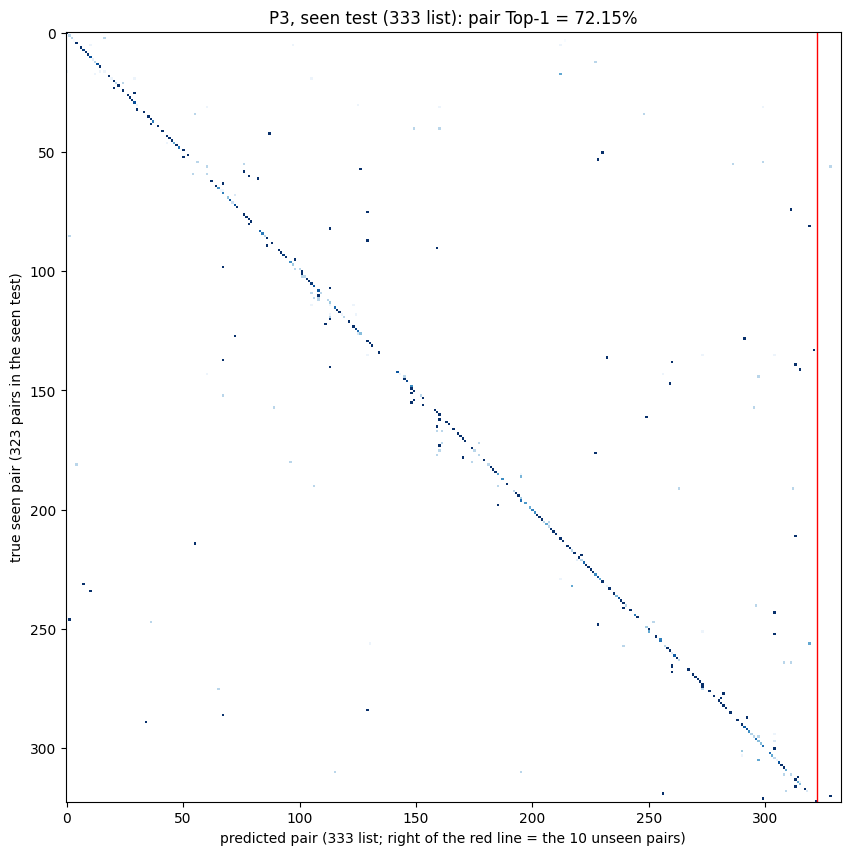

In [14]:
# Seen test images: true pair (rows) against P3's predicted pair (columns, 333 list, raw). The diagonal is each pair's accuracy.
catalogue = json.loads(CAT_FINAL_PATH.read_text())['pairs']
conf, rows_pairs, pairs = ens.seen_confusion(HEADS['P3']['seen'][0], HEADS['P3']['seen'][1], test['seen'], catalogue,
                                            CROP_IDS, DISEASE_IDS, ALLOWED_333)
np.save(RESULTS / 'confusion_seen_333_P3.npy', conf)
fig, ax = plt.subplots(figsize=(10, 10))
cmap = plt.get_cmap('Blues').copy()
cmap.set_under('white')
ax.imshow(conf, cmap=cmap, vmin=0.3, vmax=1, aspect='auto', interpolation='nearest')
ax.axvline(sum(p['is_seen'] for p in catalogue) - 0.5, color='red', lw=1)
ax.set_xlabel('predicted pair (333 list; right of the red line = the 10 unseen pairs)')
ax.set_ylabel(f'true seen pair ({len(rows_pairs)} pairs in the seen test)')
ax.set_title(f'P3, seen test (333 list): pair Top-1 = {100 * METRICS["P3"][ens.LIST_333, "seen"]["composition_top1"]:.2f}%')
fig.savefig(RESULTS / 'confusion_seen_333_P3.png', dpi=150)
plt.show()

## 10. Save everything to Drive

In [15]:
save_results(OUT, DRIVE_RESULTS, model_folders=('stage2',), retries=10, wait=30)
drive.flush_and_unmount()                      # finish the background upload before closing
print('Finished. Results are in My Drive/DPD-Small/final_model_results. You can close this tab.')

saved 146 new or changed files to /content/drive/MyDrive/DPD-Small/final_model_results
Finished. Results are in My Drive/DPD-Small/final_model_results. You can close this tab.
